In [1]:
import pandas as pd

# Load the raw resume dataset
resumes_df = pd.read_csv("../data/raw/resumes.csv")

print("Dataset loaded successfully!")
print("Shape:", resumes_df.shape)

Dataset loaded successfully!
Shape: (1200, 3)


In [2]:
import re

def clean_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [3]:
sample_text = resumes_df.loc[0, "resume_text"]

print("Original Resume:")
print(sample_text)

print("\nCleaned Resume:")
print(clean_text(sample_text))

Original Resume:
Experienced professional interested in AI/ML Engineer. Skills include Python, PyTorch, Machine Learning, NumPy, NLP, Project Management. Worked on academic and practical projects involving Python, PyTorch, Machine Learning, NumPy. Familiar with software development practices, problem solving and teamwork.

Cleaned Resume:
experienced professional interested in ai ml engineer skills include python pytorch machine learning numpy nlp project management worked on academic and practical projects involving python pytorch machine learning numpy familiar with software development practices problem solving and teamwork


In [4]:
# Apply text cleaning to all resumes

resumes_df["cleaned_resume_text"] = resumes_df["resume_text"].apply(clean_text)

print("Text preprocessing completed!")
print("Number of resumes processed:", len(resumes_df))

Text preprocessing completed!
Number of resumes processed: 1200


In [5]:
resumes_df[
    ["resume_id", "resume_text", "cleaned_resume_text"]
].head()

,resume_id,resume_text,cleaned_resume_text
0,R0001,Experienced professional interested in AI/ML E...,experienced professional interested in ai ml e...
1,R0002,Experienced professional interested in AI/ML E...,experienced professional interested in ai ml e...
2,R0003,Experienced professional interested in AI/ML E...,experienced professional interested in ai ml e...
3,R0004,Experienced professional interested in AI/ML E...,experienced professional interested in ai ml e...
4,R0005,Experienced professional interested in AI/ML E...,experienced professional interested in ai ml e...


In [6]:
from pathlib import Path

# Create the processed data folder
processed_path = Path("../data/processed")
processed_path.mkdir(parents=True, exist_ok=True)

# Save the cleaned dataset
cleaned_file = processed_path / "cleaned_resumes.csv"
resumes_df.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved successfully!")
print("Location:", cleaned_file)

Cleaned dataset saved successfully!
Location: ..\data\processed\cleaned_resumes.csv


In [7]:
import pandas as pd

# Load the saved cleaned dataset
cleaned_df = pd.read_csv("../data/processed/cleaned_resumes.csv")

print("Cleaned dataset loaded successfully!")
print("Shape:", cleaned_df.shape)
print("\nColumns:")
print(cleaned_df.columns.tolist())

Cleaned dataset loaded successfully!
Shape: (1200, 4)

Columns:
['resume_id', 'resume_text', 'job_category', 'cleaned_resume_text']


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

print("TF-IDF library imported successfully!")

TF-IDF library imported successfully!


In [9]:
vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

print("TF-IDF vectorizer created successfully!")

TF-IDF vectorizer created successfully!


In [10]:
tfidf_matrix = vectorizer.fit_transform(
    cleaned_df["cleaned_resume_text"]
)

print("TF-IDF transformation completed!")
print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF transformation completed!
TF-IDF matrix shape: (1200, 106)


In [11]:
print("Number of TF-IDF features:", len(vectorizer.get_feature_names_out()))

print("\nFirst 20 TF-IDF features:")
print(vectorizer.get_feature_names_out()[:20])

Number of TF-IDF features: 106

First 20 TF-IDF features:
['academic' 'administrator' 'agile' 'ai' 'algorithms' 'analysis' 'analyst'
 'android' 'api' 'app' 'assessment' 'automation' 'aws' 'azure' 'backup'
 'bi' 'business' 'cd' 'ci' 'cloud']


In [12]:
import joblib
from pathlib import Path

models_path = Path("../models")
models_path.mkdir(parents=True, exist_ok=True)

vectorizer_path = models_path / "tfidf_vectorizer.pkl"

joblib.dump(vectorizer, vectorizer_path)

print("TF-IDF vectorizer saved successfully!")
print("Location:", vectorizer_path)

TF-IDF vectorizer saved successfully!
Location: ..\models\tfidf_vectorizer.pkl


In [13]:
# Check whether job category names appear directly in resume text

categories = cleaned_df["job_category"].unique()

for category in categories:
    count = cleaned_df["cleaned_resume_text"].str.contains(
        category.lower(),
        regex=False
    ).sum()

    print(f"{category}: {count} resumes")

AI/ML Engineer: 0 resumes
Data Analyst: 100 resumes
Data Scientist: 100 resumes
Software Developer: 100 resumes
Web Developer: 100 resumes
Cybersecurity Analyst: 100 resumes
Cloud Engineer: 100 resumes
Database Administrator: 100 resumes
DevOps Engineer: 100 resumes
Mobile App Developer: 100 resumes
QA/Test Engineer: 0 resumes
Business Analyst: 100 resumes


In [14]:
# Remove job category names from resume text to prevent target leakage

def remove_category_name(text, category):
    category_clean = clean_text(category)
    text = text.replace(category_clean, " ")
    text = re.sub(r"\s+", " ", text).strip()
    return text


cleaned_df["cleaned_resume_text"] = cleaned_df.apply(
    lambda row: remove_category_name(
        row["cleaned_resume_text"],
        row["job_category"]
    ),
    axis=1
)

print("Category names removed from resume text!")

Category names removed from resume text!


In [15]:
# Verify that job category names are no longer present

for category in categories:
    count = cleaned_df["cleaned_resume_text"].str.contains(
        clean_text(category),
        regex=False
    ).sum()

    print(f"{category}: {count} resumes")

AI/ML Engineer: 0 resumes
Data Analyst: 0 resumes
Data Scientist: 0 resumes
Software Developer: 0 resumes
Web Developer: 0 resumes
Cybersecurity Analyst: 0 resumes
Cloud Engineer: 0 resumes
Database Administrator: 0 resumes
DevOps Engineer: 0 resumes
Mobile App Developer: 0 resumes
QA/Test Engineer: 0 resumes
Business Analyst: 0 resumes


In [16]:
# Recreate TF-IDF features using the corrected resume text

tfidf_matrix = vectorizer.fit_transform(
    cleaned_df["cleaned_resume_text"]
)

print("TF-IDF features recreated successfully!")
print("New TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF features recreated successfully!
New TF-IDF matrix shape: (1200, 96)


In [17]:
from sklearn.model_selection import train_test_split

X = tfidf_matrix
y = cleaned_df["job_category"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset split successfully!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Dataset split successfully!
Training samples: 960
Testing samples: 240


In [18]:
from sklearn.linear_model import LogisticRegression

# Create the model
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Job category model trained successfully!")

Job category model trained successfully!


In [19]:
# Predict job categories for the test data
y_pred = model.predict(X_test)

print("Predictions completed!")
print("Number of predictions:", len(y_pred))

Predictions completed!
Number of predictions: 240


In [20]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Job Category Prediction Accuracy:")
print(f"{accuracy * 100:.2f}%")

Job Category Prediction Accuracy:
99.58%


In [21]:
from sklearn.metrics import classification_report

report = classification_report(y_test, y_pred)

print("Classification Report:")
print(report)

Classification Report:
                        precision    recall  f1-score   support

        AI/ML Engineer       1.00      0.95      0.97        20
      Business Analyst       1.00      1.00      1.00        20
        Cloud Engineer       1.00      1.00      1.00        20
 Cybersecurity Analyst       1.00      1.00      1.00        20
          Data Analyst       1.00      1.00      1.00        20
        Data Scientist       0.95      1.00      0.98        20
Database Administrator       1.00      1.00      1.00        20
       DevOps Engineer       1.00      1.00      1.00        20
  Mobile App Developer       1.00      1.00      1.00        20
      QA/Test Engineer       1.00      1.00      1.00        20
    Software Developer       1.00      1.00      1.00        20
         Web Developer       1.00      1.00      1.00        20

              accuracy                           1.00       240
             macro avg       1.00      1.00      1.00       240
          weigh

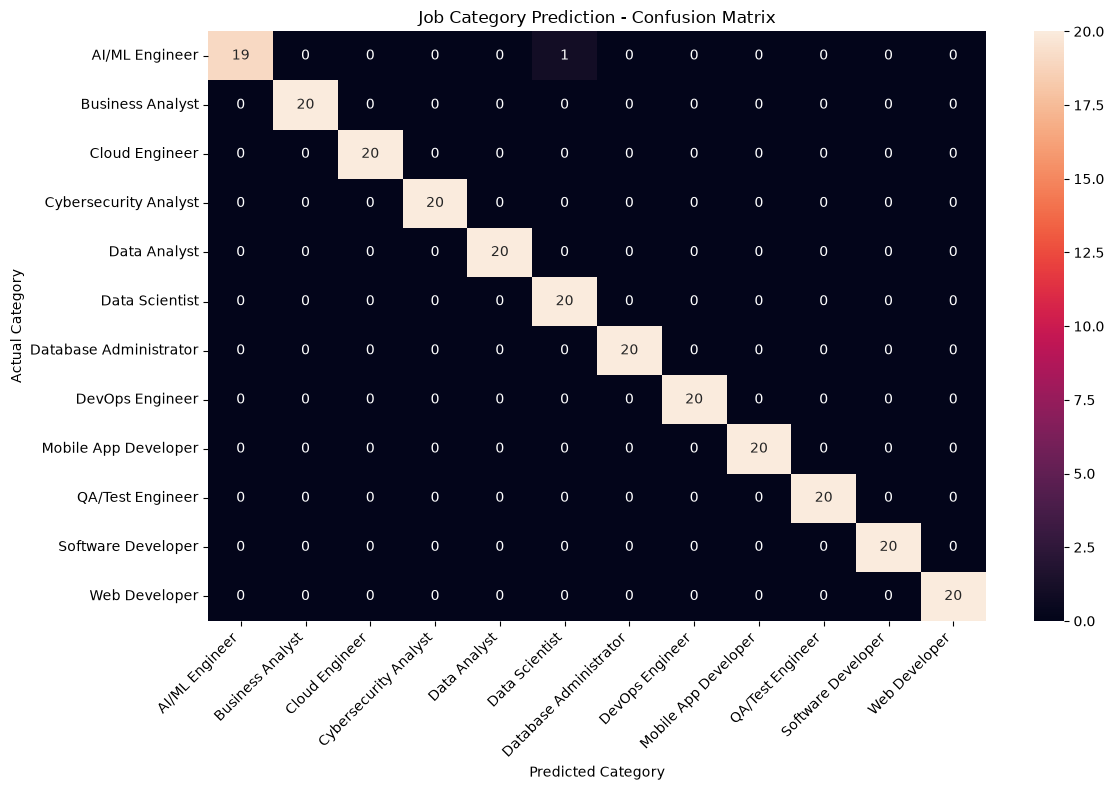

In [22]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred, labels=model.classes_)

plt.figure(figsize=(12, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Job Category Prediction - Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
import joblib

vectorizer_path = "../models/tfidf_vectorizer.pkl"

joblib.dump(vectorizer, vectorizer_path)

print("Corrected TF-IDF vectorizer saved successfully!")
print("Location:", vectorizer_path)

Corrected TF-IDF vectorizer saved successfully!
Location: ../models/tfidf_vectorizer.pkl


In [24]:
import joblib

model_path = "../models/job_category_model.pkl"

joblib.dump(model, model_path)

print("Job category model saved successfully!")
print("Location:", model_path)

Job category model saved successfully!
Location: ../models/job_category_model.pkl


In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

from text_preprocessing import clean_text

print("Text preprocessing imported successfully!")

Text preprocessing imported successfully!


In [2]:
test_text = "Python, MACHINE Learning!!! Pandas & NumPy 123."

cleaned_text = clean_text(test_text)

print("Original:")
print(test_text)

print("\nCleaned:")
print(cleaned_text)

Original:
Python, MACHINE Learning!!! Pandas & NumPy 123.

Cleaned:
python machine learning pandas numpy
